In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería (notebooks/colecciones/<coleccion>/ -> ../../../src)
sys.path.append(os.path.abspath('../../../src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones se adjunta, con la duración normal y la duración tope de cada actividad (semanas) y el coste directo (k€) de ejecutarla en cada una. Además, el proyecto tiene unos costes indirectos (oficina, alquileres, seguros) de 9 k€ por semana de duración.

In [3]:
pregunta_1 = "1. Calcule el coste unitario de reducción (CUR) de cada actividad.  "
pregunta_2 = "2. Determine la duración normal del proyecto y su coste total (directo más indirecto).  "
pregunta_3 = "3. Aplique el algoritmo de Ackoff-Sasieni hasta alcanzar la duración tope del proyecto, anotando en cada paso el sobrecoste directo.  "
pregunta_4 = "4. Construya la curva de coste total frente a duración y determine la duración de coste mínimo. ¿Qué regla de parada se deduce comparando el CUR del paso con el coste indirecto semanal?  "
pregunta_5 = "5. ¿Por qué no se puede reducir el proyecto por debajo de su duración tope aunque queden actividades con margen de reducción?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule el coste unitario de reducción (CUR) de cada actividad.  

2. Determine la duración normal del proyecto y su coste total (directo más indirecto).  

3. Aplique el algoritmo de Ackoff-Sasieni hasta alcanzar la duración tope del proyecto, anotando en cada paso el sobrecoste directo.  

4. Construya la curva de coste total frente a duración y determine la duración de coste mínimo. ¿Qué regla de parada se deduce comparando el CUR del paso con el coste indirecto semanal?  

5. ¿Por qué no se puede reducir el proyecto por debajo de su duración tope aunque queden actividades con margen de reducción?  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, cap_duration, cost_normal, cost_cap
    ('A'     , '---'      , 3       , 1           , 90         , 98      ),
    ('B'     , '---'      , 6       , 5           , 30         , 35      ),
    ('C'     , '---'      , 2       , 1           , 40         , 42      ),
    ('D'     , 'B'        , 6       , 3           , 60         , 84      ),
    ('E'     , 'A,C,D'    , 5       , 3           , 90         , 108     ),
    ('F'     , 'E'        , 4       , 2           , 60         , 64      ),
    ('G'     , 'E'        , 8       , 7           , 20         , 28      ),
    ('H'     , 'G'        , 8       , 6           , 70         , 72      ),
], columns=['activity', 'predecessor', 'duration', 'cap_duration', 'cost_normal', 'cost_cap']).set_index('activity')
datos_enunciado

,predecessor,duration,cap_duration,cost_normal,cost_cap
activity,,,,,
A,---,3,1,90,98
B,---,6,5,30,35
C,---,2,1,40,42
D,B,6,3,60,84
E,"A,C,D",5,3,90,108
F,E,4,2,60,64
G,E,8,7,20,28
H,G,8,6,70,72


# Resolución

In [5]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [6]:
display(Markdown(pregunta_1))

1. Calcule el coste unitario de reducción (CUR) de cada actividad.  

$CUR = \dfrac{\text{coste tope} - \text{coste normal}}{\text{duración normal} - \text{duración tope}}$. Las actividades cuya duración tope coincide con la normal no pueden acortarse: su CUR es infinito.

In [7]:
reducible = datos_proyecto['duration'] > datos_proyecto['cap_duration']
datos_proyecto['ucr'] = np.where(reducible,
                                 (datos_proyecto['cost_cap'] - datos_proyecto['cost_normal']) / (datos_proyecto['duration'] - datos_proyecto['cap_duration']).replace(0, np.nan),
                                 np.inf)
datos_proyecto[['duration', 'cap_duration', 'cost_normal', 'cost_cap', 'ucr']]

,duration,cap_duration,cost_normal,cost_cap,ucr
activity,,,,,
A,3,1,90,98,4.0
B,6,5,30,35,5.0
C,2,1,40,42,2.0
D,6,3,60,84,8.0
E,5,3,90,108,9.0
F,4,2,60,64,2.0
G,8,7,20,28,8.0
H,8,6,70,72,1.0


## Apartado 2

In [8]:
display(Markdown(pregunta_2))

2. Determine la duración normal del proyecto y su coste total (directo más indirecto).  

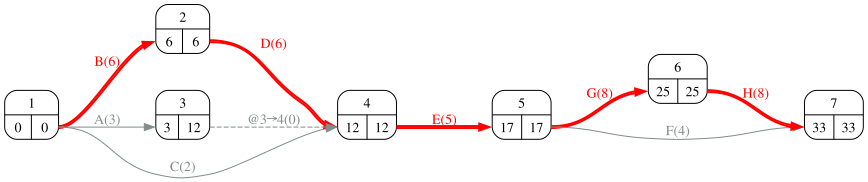

In [9]:
#| fig-cap: "Grafo PERT con las duraciones normales y el camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [10]:
coste_indirecto_semanal = 9
duracion_normal = proyecto.duration(datos_proyecto['duration'])
coste_directo_normal = int(datos_proyecto['cost_normal'].sum())
camino_critico = proyecto.display_critical_path(datos_proyecto['duration'])
Markdown(f'Duración normal: {duracion_normal} semanas. Coste directo {coste_directo_normal} k€ + indirecto '
         f'{coste_indirecto_semanal} × {duracion_normal} = {coste_indirecto_semanal * duracion_normal} k€; total '
         f'{coste_directo_normal + coste_indirecto_semanal * duracion_normal} k€.')

- Route_4 :	B, D, E, G, H <br> 

Duración normal: 33 semanas. Coste directo 460 k€ + indirecto 9 × 33 = 297 k€; total 757 k€.

## Apartado 3

In [11]:
display(Markdown(pregunta_3))

3. Aplique el algoritmo de Ackoff-Sasieni hasta alcanzar la duración tope del proyecto, anotando en cada paso el sobrecoste directo.  

En cada paso del algoritmo de Ackoff-Sasieni se acorta una semana la ruta (o rutas) crítica(s) eligiendo, entre las actividades críticas con margen, la combinación de menor CUR que reduzca *todas* las rutas críticas a la vez. Cuando hay varias rutas críticas sin actividades comunes baratas hay que acortar una actividad de cada una, y el coste del paso es la suma. La tabla muestra, para cada ruta, el CUR de sus actividades y su duración tras cada paso; las últimas filas, el margen de reducción que le queda a cada actividad.

In [12]:
#| tbl-cap: "Algoritmo de Ackoff-Sasieni"
#| label: tbl-ackoff
tabla_ackoff, pasos, duraciones_reducidas, margen_restante = proyecto.ackoff(
    durations=datos_proyecto['duration'], min_durations=datos_proyecto['cap_duration'],
    costs=datos_proyecto['ucr'], reduction=100, report=False)
tabla_ackoff

,A,B,C,D,E,F,G,H,0,1,2,3,4,5,6,7,8,9
Route_1,4.0,,,,9.0,2.0,,,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,11.0,10.0
Route_2,4.0,,,,9.0,,8.0,1.0,24.0,23.0,22.0,22.0,22.0,22.0,22.0,21.0,20.0,19.0
Route_3,,5.0,,8.0,9.0,2.0,,,21.0,21.0,21.0,20.0,19.0,18.0,17.0,17.0,16.0,15.0
Route_4,,5.0,,8.0,9.0,,8.0,1.0,33.0,32.0,31.0,30.0,29.0,28.0,27.0,26.0,25.0,24.0
Route_5,,,2.0,,9.0,2.0,,,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,10.0,9.0
Route_6,,,2.0,,9.0,,8.0,1.0,23.0,22.0,21.0,21.0,21.0,21.0,21.0,20.0,19.0,18.0
0,2.0,1.0,1.0,3.0,2.0,2.0,1.0,2.0,,,,,,,,,,
1,2.0,1.0,1.0,3.0,2.0,2.0,1.0,1.0,,,,,,,,,,
2,2.0,1.0,1.0,3.0,2.0,2.0,1.0,0.0,,,,,,,,,,
3,2.0,0.0,1.0,3.0,2.0,2.0,1.0,0.0,,,,,,,,,,


In [13]:
resumen = pd.DataFrame({'actividades acortadas': [', '.join(acts) for acts in pasos.values()],
                        'sobrecoste del paso': [sum(datos_proyecto.loc[acts, 'ucr']) for acts in pasos.values()]},
                       index=pd.Index(range(1, len(pasos) + 1), name='paso'))
resumen['duración'] = duracion_normal - resumen.index
resumen['sobrecoste acumulado'] = resumen['sobrecoste del paso'].cumsum()
resumen

,actividades acortadas,sobrecoste del paso,duración,sobrecoste acumulado
paso,,,,
1,H,1.0,32,1.0
2,H,1.0,31,2.0
3,B,5.0,30,7.0
4,D,8.0,29,15.0
5,D,8.0,28,23.0
6,D,8.0,27,31.0
7,G,8.0,26,39.0
8,E,9.0,25,48.0
9,E,9.0,24,57.0


## Apartado 4

In [14]:
display(Markdown(pregunta_4))

4. Construya la curva de coste total frente a duración y determine la duración de coste mínimo. ¿Qué regla de parada se deduce comparando el CUR del paso con el coste indirecto semanal?  

In [15]:
curva = pd.DataFrame({'duración': [duracion_normal] + resumen['duración'].tolist(),
                      'coste directo': [coste_directo_normal] + (coste_directo_normal + resumen['sobrecoste acumulado']).tolist()})
curva['coste indirecto'] = coste_indirecto_semanal * curva['duración']
curva['coste total'] = curva['coste directo'] + curva['coste indirecto']
curva = curva.set_index('duración')
curva

,coste directo,coste indirecto,coste total
duración,,,
33,460.0,297,757.0
32,461.0,288,749.0
31,462.0,279,741.0
30,467.0,270,737.0
29,475.0,261,736.0
28,483.0,252,735.0
27,491.0,243,734.0
26,499.0,234,733.0
25,508.0,225,733.0


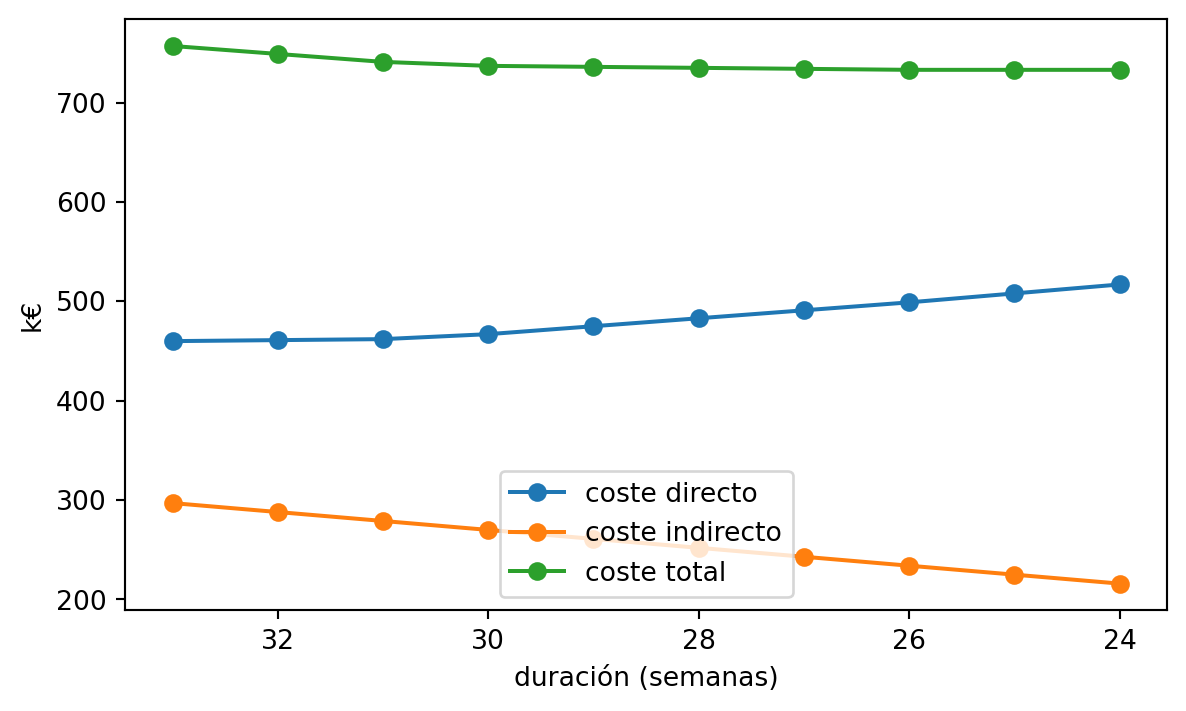

In [16]:
#| fig-cap: "Curva coste-duración del proyecto"
#| label: fig-curvaCoste
ax = curva.plot(marker='o', figsize=(7, 4))
ax.set_ylabel('k€'); ax.set_xlabel('duración (semanas)'); ax.invert_xaxis();

In [17]:
duracion_optima = int(curva['coste total'].idxmin())
Markdown(f'''El coste total es mínimo, {curva["coste total"].min():.0f} k€, para una duración de {duracion_optima} semanas. Cada semana de reducción cuesta el CUR del paso y ahorra {coste_indirecto_semanal} k€ de indirectos, así que compensa reducir mientras el sobrecoste del paso sea menor que {coste_indirecto_semanal}; como los pasos de Ackoff-Sasieni tienden a ser cada vez más caros, en cuanto el CUR del paso supera el coste indirecto semanal se para (conviene comprobar la tabla completa por si un paso posterior volviera a ser barato).''')

El coste total es mínimo, 733 k€, para una duración de 26 semanas. Cada semana de reducción cuesta el CUR del paso y ahorra 9 k€ de indirectos, así que compensa reducir mientras el sobrecoste del paso sea menor que 9; como los pasos de Ackoff-Sasieni tienden a ser cada vez más caros, en cuanto el CUR del paso supera el coste indirecto semanal se para (conviene comprobar la tabla completa por si un paso posterior volviera a ser barato).

## Apartado 5

In [18]:
display(Markdown(pregunta_5))

5. ¿Por qué no se puede reducir el proyecto por debajo de su duración tope aunque queden actividades con margen de reducción?  

In [19]:
Markdown(f'''La duración tope del proyecto, {duracion_normal - len(pasos)} semanas, se alcanza cuando todas las actividades de alguna ruta crítica están en su duración tope: esa ruta ya no puede acortarse y marca la duración mínima, aunque otras actividades (de otras rutas, o críticas pero no de esa ruta) conserven margen. Margen que queda por actividad: {{a: int(m) for a, m in margen_restante[margen_restante > 0].items()}}.''')

La duración tope del proyecto, 24 semanas, se alcanza cuando todas las actividades de alguna ruta crítica están en su duración tope: esa ruta ya no puede acortarse y marca la duración mínima, aunque otras actividades (de otras rutas, o críticas pero no de esa ruta) conserven margen. Margen que queda por actividad: {a: int(m) for a, m in margen_restante[margen_restante > 0].items()}.